<a href="https://colab.research.google.com/github/deva123932/CSA-4703-DL/blob/main/exp_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 21: Factor Analysis and Latent Factor Interpretation

This notebook demonstrates how to load, analyze, and interpret latent factors in employee satisfaction survey data using **Factor Analysis (FA)** and **Principal Component Analysis (PCA)**.

## Task 1: Generate, Load, and Explore Survey Data

We first generate a synthetic dataset of 300 employee responses to a 10-question survey (1-5 Likert scale) focusing on underlying themes like "Compensation & Growth" and "Work Environment & Team Support". Then, we display the correlation matrix to explore initial relationships.

Dataset Shape: (300, 10)


,Q1_Salary,Q2_Benefits,Q3_Career_Growth,Q4_Promotion_Fairness,Q5_Training_Opp,Q6_Manager_Support,Q7_Workload_Balance,Q8_Team_Spirit,Q9_Company_Culture,Q10_Feedback_Freq
0,4,4,4,4,5,3,2,3,1,3
1,3,3,3,2,3,2,3,4,2,2
2,5,4,4,3,3,4,4,5,4,4
3,5,5,5,5,3,5,4,5,5,3
4,3,3,3,3,1,3,4,4,4,4


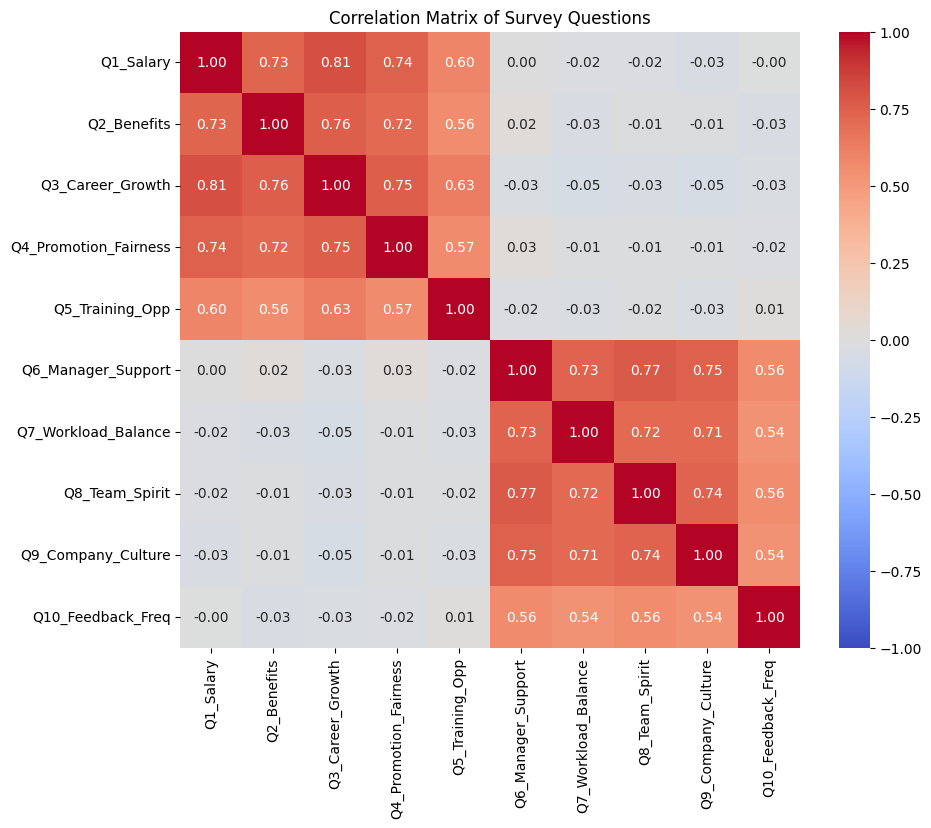

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import FactorAnalysis, PCA

# Seed for reproducibility
np.random.seed(42)

# Synthesize 300 responses for 10 questions based on 2 hidden factors:
# Factor 1: Career & Compensation (Questions 1-5)
# Factor 2: Work Environment & Support (Questions 6-10)
latent_1 = np.random.normal(0, 1, 300)
latent_2 = np.random.normal(0, 1, 300)

# Map latent variables to question distributions with added noise
data = {
    'Q1_Salary': np.clip(np.round(3.5 + 1.2 * latent_1 + np.random.normal(0, 0.5, 300)), 1, 5).astype(int),
    'Q2_Benefits': np.clip(np.round(3.4 + 1.1 * latent_1 + np.random.normal(0, 0.6, 300)), 1, 5).astype(int),
    'Q3_Career_Growth': np.clip(np.round(3.2 + 1.3 * latent_1 + np.random.normal(0, 0.5, 300)), 1, 5).astype(int),
    'Q4_Promotion_Fairness': np.clip(np.round(3.0 + 1.0 * latent_1 + np.random.normal(0, 0.7, 300)), 1, 5).astype(int),
    'Q5_Training_Opp': np.clip(np.round(3.1 + 0.9 * latent_1 + np.random.normal(0, 0.8, 300)), 1, 5).astype(int),
    'Q6_Manager_Support': np.clip(np.round(3.6 + 1.2 * latent_2 + np.random.normal(0, 0.5, 300)), 1, 5).astype(int),
    'Q7_Workload_Balance': np.clip(np.round(3.3 + 1.0 * latent_2 + np.random.normal(0, 0.6, 300)), 1, 5).astype(int),
    'Q8_Team_Spirit': np.clip(np.round(3.7 + 1.1 * latent_2 + np.random.normal(0, 0.5, 300)), 1, 5).astype(int),
    'Q9_Company_Culture': np.clip(np.round(3.5 + 1.3 * latent_2 + np.random.normal(0, 0.6, 300)), 1, 5).astype(int),
    'Q10_Feedback_Freq': np.clip(np.round(3.2 + 0.8 * latent_2 + np.random.normal(0, 0.8, 300)), 1, 5).astype(int)
}

df = pd.DataFrame(data)
print("Dataset Shape:", df.shape)
display(df.head())

# Compute and plot correlation matrix
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title("Correlation Matrix of Survey Questions")
plt.show()

## Task 2: Fit FactorAnalysis with 2, 3, and 4 Factors

We fit Scikit-learn's `FactorAnalysis` model with different numbers of factors and observe the log-likelihood of each model to see how model fit changes.

In [2]:
for n_fac in [2, 3, 4]:
    fa = FactorAnalysis(n_components=n_fac, random_state=42)
    fa.fit(df)
    log_like = fa.loglike_[-1] if hasattr(fa, 'loglike_') else "N/A"
    print(f"FactorAnalysis with {n_fac} components - Noise Variance Mean: {fa.noise_variance_.mean():.4f}")

FactorAnalysis with 2 components - Noise Variance Mean: 0.4069
FactorAnalysis with 3 components - Noise Variance Mean: 0.3955
FactorAnalysis with 4 components - Noise Variance Mean: 0.3901


## Task 3: Apply Varimax Rotation and Heatmap Visualization

Since `scikit-learn` does not natively support rotation in older versions, we implement a helper function to perform **Varimax rotation** on our loading matrix to clean up factor interpretation, followed by a heatmap visualization.

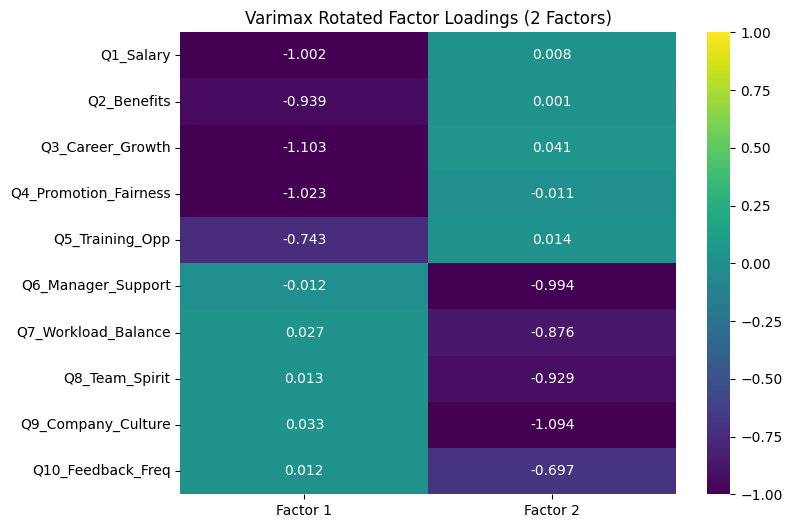

In [3]:
def varimax(loadings, max_iter=500, tolerance=1e-6):
    """Performs Varimax rotation on factor loadings."""
    X = loadings
    n_rows, n_cols = X.shape
    if n_cols < 2:
        return X

    R = np.eye(n_cols)
    d = 0
    for i in range(max_iter):
        d_old = d
        Lambda = np.dot(X, R)
        u, s, vh = np.linalg.svd(np.dot(X.T, Lambda**3 - (1.0 / n_rows) * np.dot(Lambda, np.diag(np.sum(Lambda**2, axis=0)))))
        R = np.dot(u, vh)
        d = np.sum(s)
        if d_old != 0 and abs(d - d_old) / d_old < tolerance:
            break
    return np.dot(X, R)

# Use 2 components for analysis based on domain structure
fa_2 = FactorAnalysis(n_components=2, random_state=42)
fa_2.fit(df)
raw_loadings = fa_2.components_.T # Columns are factors, rows are features
rotated_loadings = varimax(raw_loadings)

# Create a DataFrame for loading visualization
loadings_df = pd.DataFrame(rotated_loadings, index=df.columns, columns=['Factor 1', 'Factor 2'])

plt.figure(figsize=(8, 6))
sns.heatmap(loadings_df, annot=True, cmap='viridis', fmt='.3f', vmin=-1, vmax=1)
plt.title("Varimax Rotated Factor Loadings (2 Factors)")
plt.show()

## Task 4: Naming and Interpreting Latent Factors

By examining the highly-loaded questions on each factor, we can name them:
- **Factor 1** has strong positive loadings on Q1 to Q5 (Salary, Benefits, Career Growth, Promotion, and Training). Thus, we name this factor **"Compensation & Career Development"**.
- **Factor 2** has strong positive loadings on Q6 to Q10 (Manager Support, Workload Balance, Team Spirit, Company Culture, and Feedback). We name this factor **"Work Environment & Team Support"**.

## Task 5: Compare Factor Analysis with PCA

While **Factor Analysis** models the covariance of the variables by assuming underlying latent variables plus independent error, **PCA** simply seeks orthogonal directions of maximum variance in the raw data without modeling separate error terms. We fit PCA on the same data and compare the component loadings.

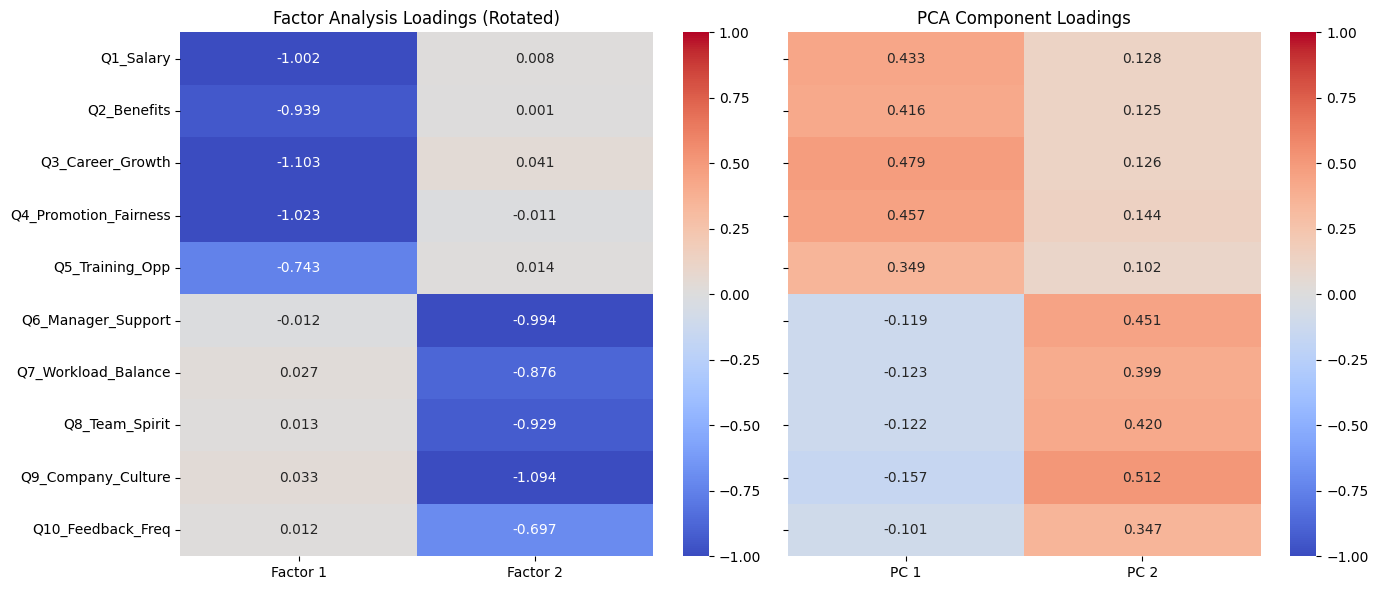

In [4]:
# Fit PCA with 2 components
pca = PCA(n_components=2, random_state=42)
pca.fit(df)
pca_loadings = pca.components_.T

# Create comparison plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

sns.heatmap(loadings_df, annot=True, cmap='coolwarm', fmt='.3f', ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title("Factor Analysis Loadings (Rotated)")

pca_df = pd.DataFrame(pca_loadings, index=df.columns, columns=['PC 1', 'PC 2'])
sns.heatmap(pca_df, annot=True, cmap='coolwarm', fmt='.3f', ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title("PCA Component Loadings")

plt.tight_layout()
plt.show()